# Bayes and kNN classifiers (forest vs urban) using Sentinel-2 true colour

**Pipeline**
1. Load any number of forest and urban training TIFFs and pool their pixels.
2. Plot the per-band histograms of each class and fit parametric (Gaussian) PDFs.
3. Bayes test on every pixel of every test TIFF: **red = forest, blue = urban**.
4. kNN classifier with k = 1, 3, 5 on the same problem, and a comparison.

In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import rasterio

# ---------------- configuration ----------------
FOREST_IMAGES = ["images/forest"]
URBAN_IMAGES  = ["images/urban"]
TEST_IMAGES   = ["images/test"]

# TIFF exported with only B4,B3,B2 in that order -> (1, 2, 3)
# Full 13-band Sentinel-2 stack (B1,B2,B3,B4,...) -> (4, 3, 2)
# If the TIFF band descriptions are named "B4","B3","B2", they are used automatically instead.
TRUE_COLOR_BANDS = (1, 2, 3)

N_PER_CLASS  = 3000     # kNN training pixels kept per class
KS           = [1, 3, 5]  # k values to compare (odd numbers)
# -----------------------------------------------

rng = np.random.default_rng()
EXTS = (".tif", ".tiff")
BAND_LABELS = ["B4 (red)", "B3 (green)", "B2 (blue)"]

def expand(patterns):
    """Finds all TIFF files matching the given patterns (files or directories) and returns a sorted list of unique file paths."""
    files = []
    for p in patterns:
        files += [os.path.join(p, f) for f in sorted(os.listdir(p)) if f.lower().endswith(EXTS)]
    return sorted(set(files))

def load_tiff(path):
    """Read the B4,B3,B2 bands of a TIFF -> float array (H,W,3) on a 0-1 scale, plus a validity mask (H,W)."""
    with rasterio.open(path) as src:
        desc = [(d or "").strip().upper() for d in src.descriptions]
        if all(b in desc for b in ("B4", "B3", "B2")):
            idx = [desc.index("B4") + 1, desc.index("B3") + 1, desc.index("B2") + 1]
        else:
            idx = list(TRUE_COLOR_BANDS)
        if max(idx) > src.count:
            raise ValueError(f"{path}: has {src.count} band(s) but TRUE_COLOR_BANDS asks for {idx}")
        data = src.read(idx).astype(np.float64)              # (3,H,W)
        nodata = src.nodata
        dtype = np.dtype(src.dtypes[0])
    img = np.moveaxis(data, 0, -1)       # (H,W,3)
    valid = np.isfinite(img).all(-1)    # (H,W) validity mask
    if nodata is not None:
        valid &= ~(img == nodata).any(-1)
    valid &= ~(img == 0).all(-1)                              # all-zero pixels = no data
    img = np.nan_to_num(img)

    # Radiometric scaling, applied identically to training and test TIFFs. Divide by the data type's maximum.
    scale = float(np.iinfo(dtype).max) if np.issubdtype(dtype, np.integer) else 1.0
    return img / scale, valid

## 0. Load images

In [2]:
# Create lists of TIFF files for each category.
forest_files, urban_files, test_files = expand(FOREST_IMAGES), expand(URBAN_IMAGES), expand(TEST_IMAGES)

# Check that we found some files, otherwise exit with an error message.
missing = []
if not forest_files: missing.append(f"forest TIFFs matching {FOREST_IMAGES}")
if not urban_files:  missing.append(f"urban TIFFs matching {URBAN_IMAGES}")
if not test_files:   missing.append(f"test TIFFs matching {TEST_IMAGES}")
if missing:
    raise SystemExit("Images not found: " + "; ".join(missing) +
                     ". Check the paths in the configuration cell.")

print(f"Forest TIFFs ({len(forest_files)}): {forest_files}")
print(f"Urban TIFFs  ({len(urban_files)}): {urban_files}")
print(f"Test TIFFs   ({len(test_files)}): {test_files}")

# Load the TIFFs into memory, returning a list of (img, valid) pairs for each category.
forest_data = [load_tiff(f) for f in forest_files]
urban_data  = [load_tiff(f) for f in urban_files]
test_data   = [load_tiff(f) for f in test_files]

def pixels(data):
    """Pool valid pixels of several (img, valid) pairs -> (N,3) matrix of [B4,B3,B2] reflectances."""
    return np.vstack([img[valid] for img, valid in data])

Xf = pixels(forest_data)   # pooled forest pixels
Xu = pixels(urban_data)    # pooled urban pixels
print(f"Training pixels: forest = {len(Xf)}, urban = {len(Xu)}")

def show_rgb(img, valid, lo=2, hi=98):
    """Percentile-stretched true-colour preview (display only)."""
    out = np.zeros_like(img)
    if valid.any():
        a, b = np.percentile(img[valid], [lo, hi])
        out = np.clip((img - a) / max(b - a, 1e-12), 0, 1)
    out[~valid] = 0
    return out

Forest TIFFs (3): ['images/forest/forest1.tiff', 'images/forest/forest2.tiff', 'images/forest/forest3.tiff']
Urban TIFFs  (3): ['images/urban/urban1.tiff', 'images/urban/urban2.tiff', 'images/urban/urban3.tiff']
Test TIFFs   (3): ['images/test/test1.tiff', 'images/test/test2.tiff', 'images/test/test3.tiff']
Training pixels: forest = 412853, urban = 195375


## 1. Histograms and parametric models

The feature vector of a pixel is $x=(\text{B4},\text{B3},\text{B2})$. Each class-conditional PDF is modelled as a Gaussian, $p(x\mid c)=\mathcal N(\mu_c,\Sigma_c)$, with the maximum-likelihood estimates (sample mean and covariance of the class pixels).
The histograms below show each band separately, with the marginal of the fitted Gaussian drawn on top.

In [3]:
def fit_gaussian(X):
    """Fit a multivariate Gaussian to the data X -> (mu, cov)."""
    mu = X.mean(axis=0)
    cov = np.atleast_2d(np.cov(X, rowvar=False)) + 1e-10 * np.eye(X.shape[1])   # tiny ridge for stability
    return mu, cov

def log_gauss(X, mu, cov):
    """Calculate the log-likelihood of each row of X under a multivariate Gaussian (mu, cov)."""
    d = X.shape[1]
    diff = X - mu
    sol = np.linalg.solve(cov, diff.T).T
    maha = np.sum(diff * sol, axis=1)                  # squared Mahalanobis distance
    _, logdet = np.linalg.slogdet(cov)
    return -0.5 * (maha + logdet + d * np.log(2 * np.pi))

mu_f, cov_f = fit_gaussian(Xf)
mu_u, cov_u = fit_gaussian(Xu)
print("Forest: mu [B4,B3,B2] =", mu_f.round(4), "\ncov =\n", cov_f.round(6))
print("Urban : mu [B4,B3,B2] =", mu_u.round(4), "\ncov =\n", cov_u.round(6))

Forest: mu [B4,B3,B2] = [0.2066 0.2425 0.2144] 
cov =
 [[0.014455 0.008405 0.00841 ]
 [0.008405 0.007492 0.005281]
 [0.00841  0.005281 0.007739]]
Urban : mu [B4,B3,B2] = [0.4864 0.4608 0.4033] 
cov =
 [[0.015629 0.015239 0.01743 ]
 [0.015239 0.016602 0.018549]
 [0.01743  0.018549 0.024172]]


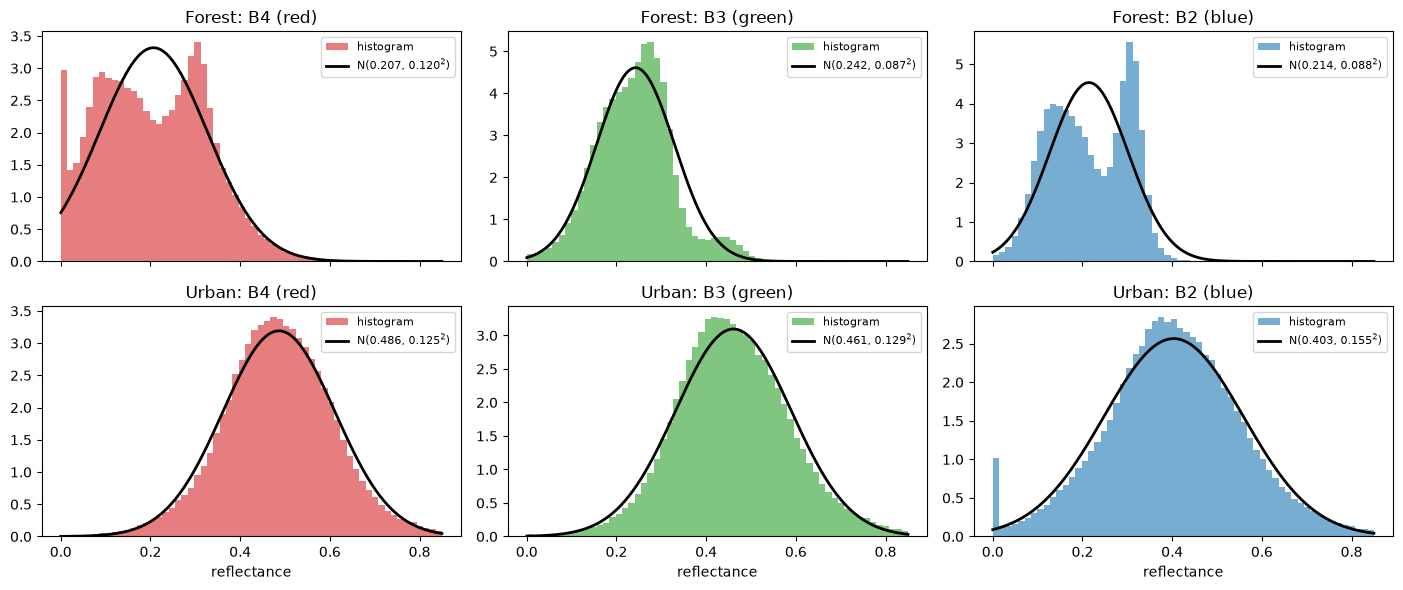

In [4]:
# Per-band histograms of each class + marginal of the fitted Gaussian
band_colors = ["tab:red", "tab:green", "tab:blue"]
lo = min(Xf.min(), Xu.min()); hi = max(np.percentile(Xf, 99.5), np.percentile(Xu, 99.5))
xs = np.linspace(lo, hi, 400)
fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex="col")
for r, (name, X, mu, cov) in enumerate([("Forest", Xf, mu_f, cov_f), ("Urban", Xu, mu_u, cov_u)]):
    for b in range(3):
        m, s = mu[b], np.sqrt(cov[b, b])
        ax[r, b].hist(X[:, b], bins=60, range=(lo, hi), density=True, alpha=.6, color=band_colors[b], label="histogram")
        ax[r, b].plot(xs, np.exp(-0.5 * ((xs - m) / s) ** 2) / (s * np.sqrt(2 * np.pi)), "k", lw=2,
                      label=f"N({m:.3f}, {s:.3f}$^2$)")
        ax[r, b].set_title(f"{name}: {BAND_LABELS[b]}"); ax[r, b].legend(fontsize=8)
        if r == 1: ax[r, b].set_xlabel("reflectance")
plt.tight_layout(); plt.show()

## 2. Bayes test

Decide **forest** if $p(x\mid F)P(F) > p(x\mid U)P(U)$, i.e. the likelihood ratio
$L(x)=p(x\mid F)/p(x\mid U) > \eta = P(U)/P(F)$.
It is computed in the log domain for numerical stability. Priors are equal by default, because the number of pixels in the training crops says nothing about how much forest is in a new scene.

In [5]:
def bayes_predict(X, prior_f=0.5):
    """Classify each row of X as forest or urban using the fitted Gaussians and a prior probability for forest."""
    log_eta = np.log(1 - prior_f) - np.log(prior_f)
    llr = log_gauss(X, mu_f, cov_f) - log_gauss(X, mu_u, cov_u)
    return np.where(llr > log_eta, 0, 1)               # 0 = forest, 1 = urban

def colorize(labels, valid):
    """Convert a 1D array of labels (0=forest, 1=urban) into a 3-channel RGB image for display, using the validity mask to ignore invalid pixels."""
    out = np.zeros((*valid.shape, 3))
    full = np.full(valid.shape, -1)
    full[valid] = labels
    out[full == 0] = [1, 0, 0]
    out[full == 1] = [0, 0, 1]
    return out

## 3. kNN classifier

For a query pixel $x$: compute the Euclidean distance (in B4, B3, B2 reflectance space) to every stored labelled pixel, take the $k$ nearest, and output the majority class.
There is no training phase, the classifier just stores data. For speed it keeps a class-balanced random subsample of the pooled pixels (`N_PER_CLASS` each).

In [6]:
nf_keep, nu_keep = min(N_PER_CLASS, len(Xf)), min(N_PER_CLASS, len(Xu))
Xtr = np.vstack([Xf[rng.choice(len(Xf), nf_keep, replace=False)],
                 Xu[rng.choice(len(Xu), nu_keep, replace=False)]])
ytr = np.r_[np.zeros(nf_keep, int), np.ones(nu_keep, int)]

def knn_predict(Xq, Xtr, ytr, k, chunk=2000):
    """Classify each row of Xq using the kNN algorithm with training data (Xtr, ytr)."""
    out = np.empty(len(Xq), int)
    for s in range(0, len(Xq), chunk):                 # chunking keeps memory bounded
        q = Xq[s:s + chunk]
        # squared Euclidean distances: |q|^2 - 2 q.t + |t|^2
        d2 = (q ** 2).sum(1)[:, None] - 2 * q @ Xtr.T + (Xtr ** 2).sum(1)[None, :]
        idx = np.argpartition(d2, k - 1, axis=1)[:, :k]            # indices of the k nearest
        votes = ytr[idx]                                            # their labels
        out[s:s + chunk] = (votes.sum(1) * 2 > k).astype(int)      # majority vote (odd k: no ties)
    return out

## 4. Classify all test images

For each test TIFF: true-colour preview, Bayes result, and kNN for each $k$ (red = forest, blue = urban, black = no data).

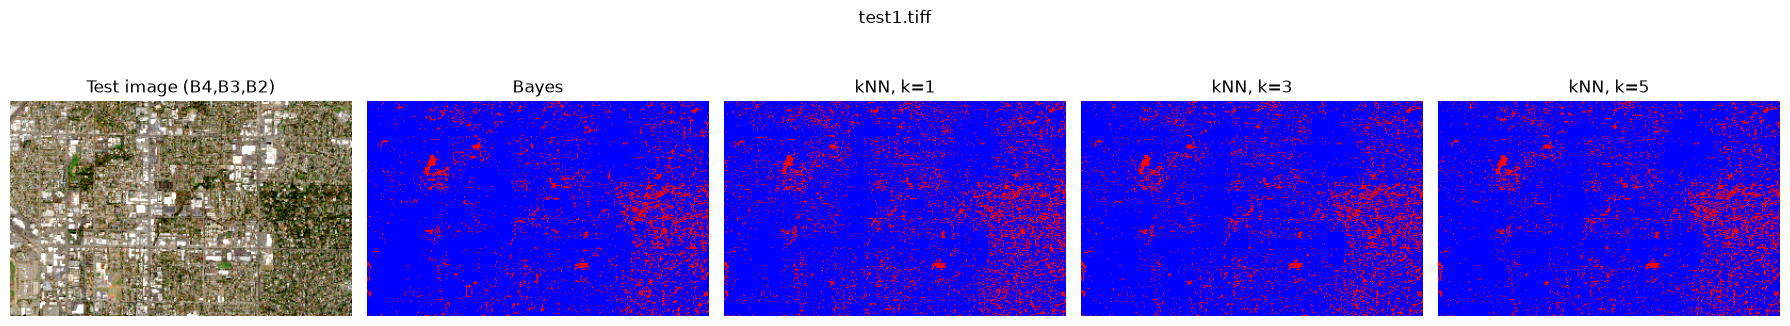

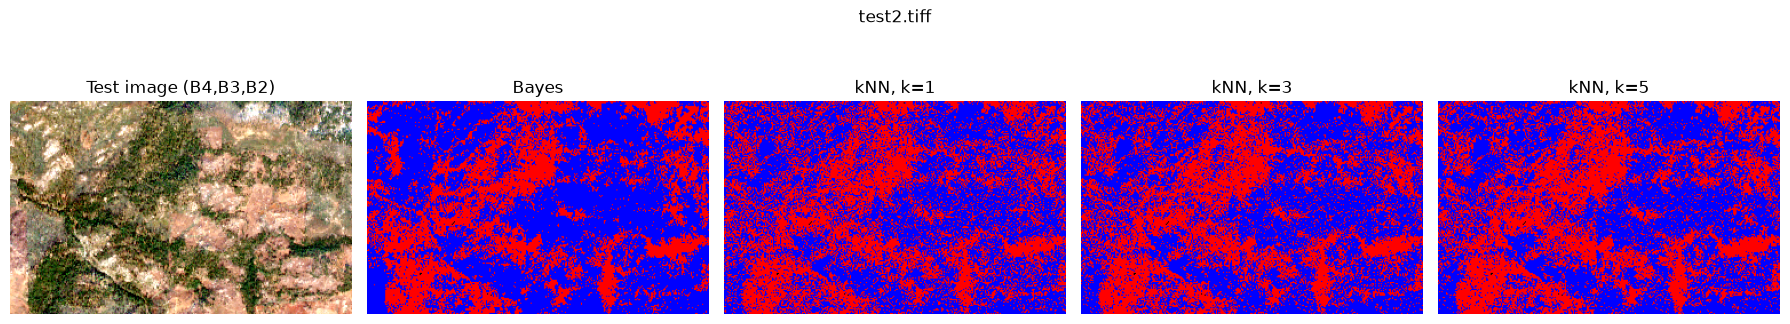

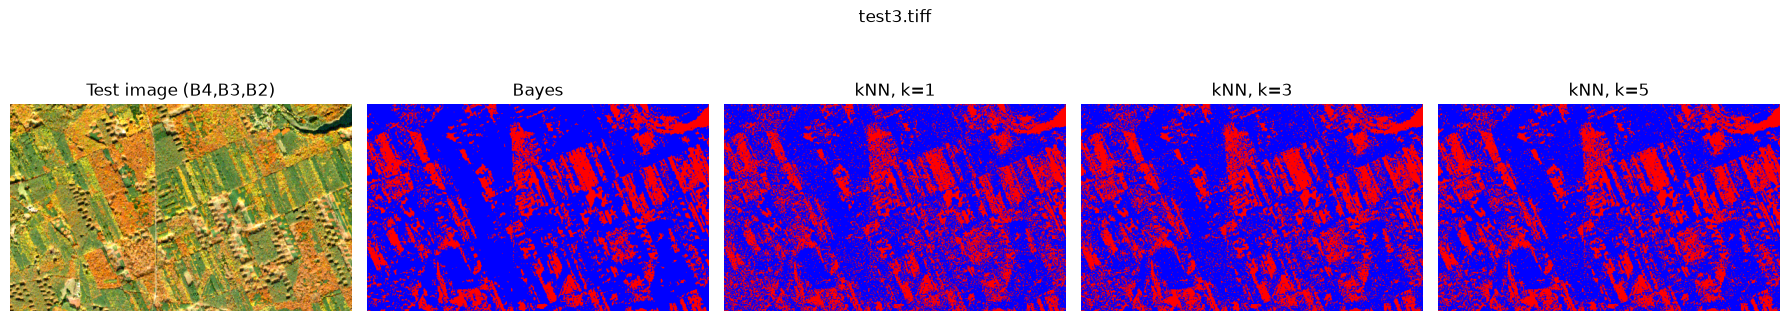

In [7]:
results = []   # one summary row per test image

for path, (img, valid) in zip(test_files, test_data):
    Xt = img[valid]
    pred_bayes = bayes_predict(Xt)
    preds = {k: knn_predict(Xt, Xtr, ytr, k) for k in KS}

    panels = [("Test image (B4,B3,B2)", show_rgb(img, valid)), ("Bayes", colorize(pred_bayes, valid))] + \
             [(f"kNN, k={k}", colorize(preds[k], valid)) for k in KS]
    fig, ax = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.8))
    for a, (title, im) in zip(ax, panels):
        a.imshow(im); a.set_title(title); a.axis("off")
    fig.suptitle(os.path.basename(path)); plt.tight_layout(); plt.show()

    row = {"image": os.path.basename(path), "Bayes % forest": 100 * (pred_bayes == 0).mean()}
    for k in KS:
        row[f"kNN k={k} % forest"] = 100 * (preds[k] == 0).mean()
        row[f"k={k} agrees w/ Bayes %"] = 100 * (preds[k] == pred_bayes).mean()
    if len(KS) > 1:
        row[f"changed k={KS[0]} to k={KS[1]} %"] = 100 * (preds[KS[0]] != preds[KS[1]]).mean()
    results.append(row)

## 5. Summary

1. The first test image is of an American city with visible vegetation from streetside trees and parks. The Bayes test proves accurate in determining the presence of **forest** pixels at the highest concentrations of greenery. The kNN tests show almost no change in comparison to the Bayes test, as well as the change in $k$ value.
2. The second test image is of a forest with large barren areas. Both the Bayes test and the kNN test mark the barren areas as **urban**. The difference lies in the kNN test having less concentrated **forest** pixels with a small $k$ than the Bayes test, spreading those pixels on a higher area with less density. Increasing the value of $k$ outputs the **forest** pixels more densily located at the areas of greatest vegetation presence, similarly to the Bayes test.
3. The third test image is of a multicolored forest, where the used algorithms only noticed the green areas as **forest** pixels (due to the training data not being varried enough). Similarly to the previous example, the kNN test with $k=1$ has more sparse pixel populations around the denser vegetation locations than the Bayes test and increasing the value of $k$ accumulates those pixels more.